In [2]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve)

In [3]:
# CARGAR MODELOS

reg_log_hta_class_weight = joblib.load("../models/reg_log_hta_class_weight.joblib")
reg_log_hta = joblib.load("../models/reg_log_hta.joblib")
reg_log_hta_smote = joblib.load("../models/reg_log_hta_smote.joblib")

In [4]:
# CARGAR LOS DATOS DE TEST 
X_test_hta = pd.read_csv("../data/processed/X_test_hta_df.csv")
y_test_hta = pd.read_csv("../data/processed/y_test_hta.csv")



# EVALUACIÓN REGRESIÓN LOGÍSTICA

INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)
              precision    recall  f1-score   support

           0     0.9072    0.7309    0.8096      2984
           1     0.5372    0.8069    0.6450      1155

    accuracy                         0.7521      4139
   macro avg     0.7222    0.7689    0.7273      4139
weighted avg     0.8040    0.7521    0.7636      4139

ROC-AUC Score: 0.8321


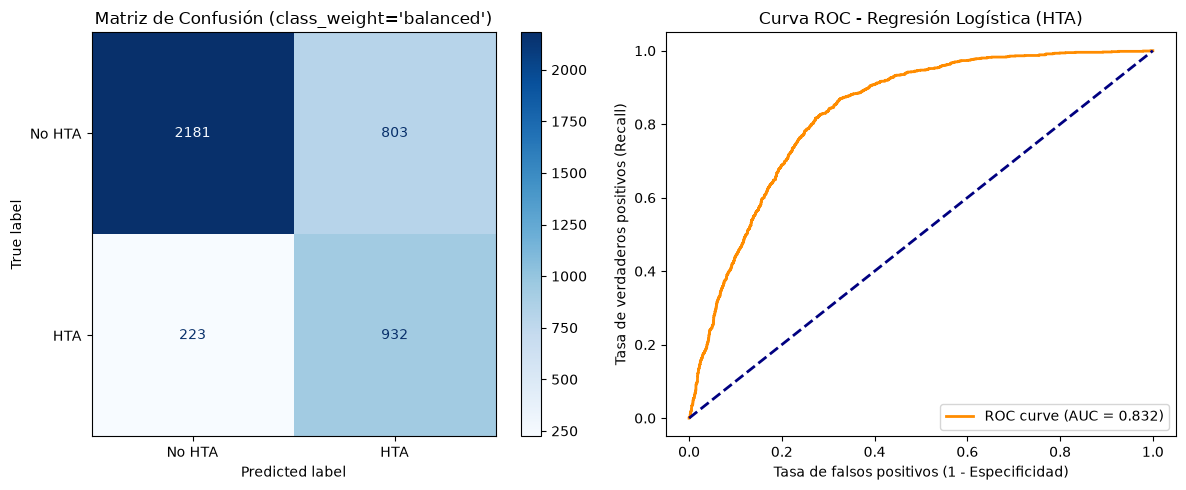

In [4]:
# ======================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS 
# ======================================================

# Predicciones 
y_pred_hta = reg_log_hta_class_weight.predict(X_test_hta)
y_pred_proba_hta = reg_log_hta_class_weight.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)")
print(classification_report(y_test_hta, y_pred_hta, digits=4))

auc_hta = roc_auc_score(y_test_hta, y_pred_proba_hta)
print(f"ROC-AUC Score: {auc_hta:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_hta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (class_weight='balanced')")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_hta, y_pred_proba_hta)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_hta:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado + Factor Adulto)
              precision    recall  f1-score   support

           0     0.9262    0.6689    0.7768      2984
           1     0.5020    0.8623    0.6346      1155

    accuracy                         0.7229      4139
   macro avg     0.7141    0.7656    0.7057      4139
weighted avg     0.8078    0.7229    0.7371      4139

ROC-AUC Score: 0.8283


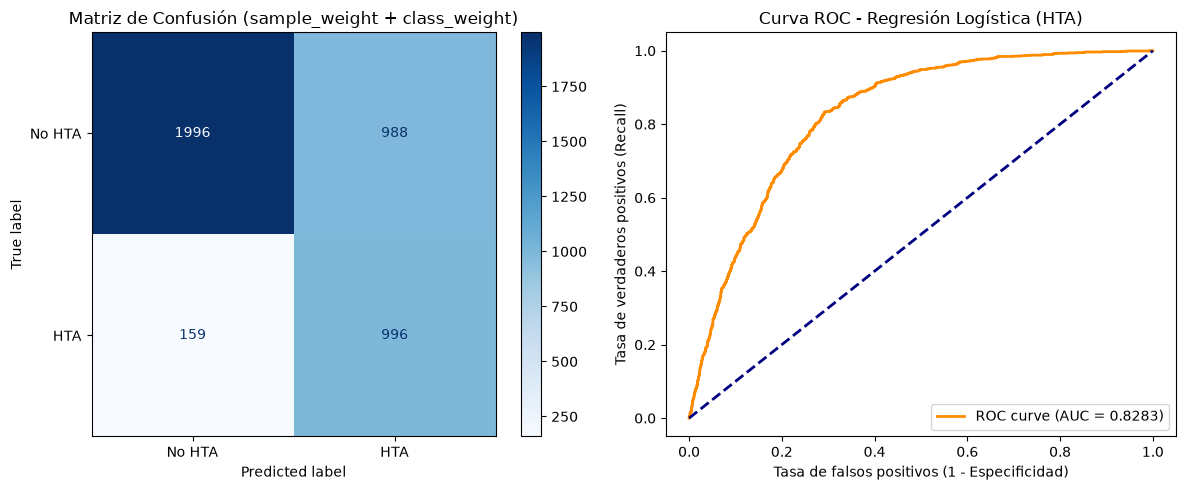

In [5]:
# =======================================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS Y FACTOR ADULTO
# =======================================================================

# Predicciones 
y_pred_hta = reg_log_hta.predict(X_test_hta)
y_pred_proba_hta = reg_log_hta.predict_proba(X_test_hta)[:, 1]

# Evaluación de métricas
print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado + Factor Adulto)")
print(classification_report(y_test_hta, y_pred_hta, digits=4))

auc_hta = roc_auc_score(y_test_hta, y_pred_proba_hta)
print(f"ROC-AUC Score: {auc_hta:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_hta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (sample_weight + class_weight)")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_hta, y_pred_proba_hta)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


In [6]:
# 1. Obtenemos las probabilidades predichas (ya entrenado con 'balanced' + sample_weight)
y_proba_hta = reg_log_hta.predict_proba(X_test_hta)[:, 1]

# 2. Probamos distintos umbrales (ejemplo: 0.40, 0.45, 0.50, 0.55)
umbrales = [0.35, 0.40, 0.45, 0.50, 0.55]

for u in umbrales:
    y_pred_u = (y_proba_hta >= u).astype(int)
    report = classification_report(
        y_test_hta, y_pred_u, digits=4, output_dict=True
    )

    rec = report["1"]["recall"]
    prec = report["1"]["precision"]
    f1 = report["1"]["f1-score"]
    acc = report["accuracy"]

    print(f"Umbral {u:.2f} -> Recall HTA: {rec*100:.2f}% | Precisión HTA: {prec*100:.2f}% | F1: {f1:.4f}% | Accuracy Global: {acc*100:.2f}")

Umbral 0.35 -> Recall HTA: 93.25% | Precisión HTA: 43.98% | F1: 0.5977% | Accuracy Global: 64.97
Umbral 0.40 -> Recall HTA: 91.60% | Precisión HTA: 46.04% | F1: 0.6128% | Accuracy Global: 67.70
Umbral 0.45 -> Recall HTA: 88.92% | Precisión HTA: 47.95% | F1: 0.6230% | Accuracy Global: 69.97
Umbral 0.50 -> Recall HTA: 86.23% | Precisión HTA: 50.20% | F1: 0.6346% | Accuracy Global: 72.29
Umbral 0.55 -> Recall HTA: 82.94% | Precisión HTA: 52.41% | F1: 0.6423% | Accuracy Global: 74.22


HIPERTENSIÓN CON SMOTE
              precision    recall  f1-score   support

           0     0.9025    0.7383    0.8122      2984
           1     0.5400    0.7939    0.6428      1155

    accuracy                         0.7538      4139
   macro avg     0.7213    0.7661    0.7275      4139
weighted avg     0.8014    0.7538    0.7649      4139

ROC-AUC Score: 0.8308


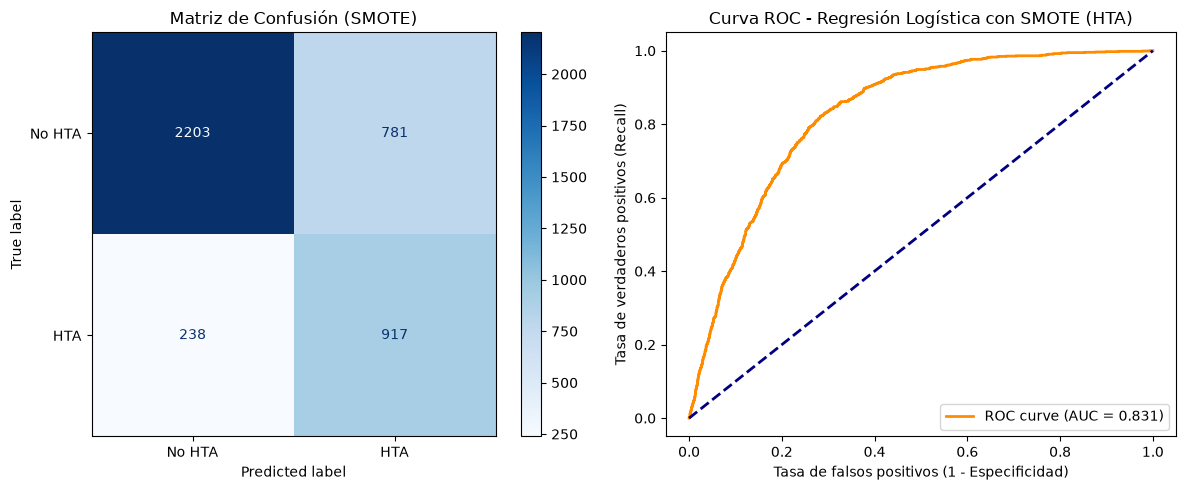

In [7]:
# ==========================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON SMOTE
# ==========================================

# Se evalua en el X_test original 
y_pred_smote = reg_log_hta_smote.predict(X_test_hta)
y_proba_smote = reg_log_hta_smote.predict_proba(X_test_hta)[:, 1]

print("HIPERTENSIÓN CON SMOTE")
print(classification_report(y_test_hta, y_pred_smote, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test_hta, y_proba_smote):.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_hta, y_pred_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No HTA", "HTA"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (SMOTE)")

# Curva ROC
fpr_smote, tpr_smote, _ = roc_curve(y_test_hta, y_proba_smote)
auc_smote = roc_auc_score(y_test_hta, y_proba_smote)
axes[1].plot(fpr_smote, tpr_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_smote:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística con SMOTE (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### CONCLUSIONES METODOLÓGICAS 

- El modelo seleccionado como Baseline es la combinación de class_weight='balanced' + sample_weight (FACTORADULTO), el cual es la opción más robusta clínicamente. Este modelo logra reducir los Falsos Negativos a solo 159 casos, mientras que el modelo que solo usa class_weight este número aumenta a 223 y 238 para el modelo con SMOTE. 

- SMOTE vs. FACTORADULTO: SMOTE incrementa ligeramente la Esepcificidad y la precision, pero al no incluir el factor de elevación de la encuesta nacional, se pierde la capacidad de detección de enfermos (Recall cae a 79,39%)

- Por ultimo, el análisis de umbrales demuestra que la mejor opción sigue siendo class_weight="balanced", o sea, 0.50

# EVALUACIÓN RANDOM FOREST

In [8]:
# Cargar modelo Random Forest
rf_hta_class_weight = joblib.load("../models/random_forest_hta_class_weight.joblib")
rf_hta = joblib.load("../models/random_forest_hta.joblib")
rf_smote_hta = joblib.load("../models/rf_smote_hta.joblib")
rf_subsample_hta = joblib.load("../models/subsample_random_forest_hta.joblib")
brf_hta = joblib.load("../models/balanced_random_forest_hta.joblib")
brf_opt = joblib.load("../models/brf_hta_opt.joblib")

INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA)
              precision    recall  f1-score   support

           0     0.8712    0.7979    0.8330      2984
           1     0.5711    0.6952    0.6271      1155

    accuracy                         0.7693      4139
   macro avg     0.7212    0.7466    0.7300      4139
weighted avg     0.7875    0.7693    0.7755      4139

ROC-AUC Score: 0.8324


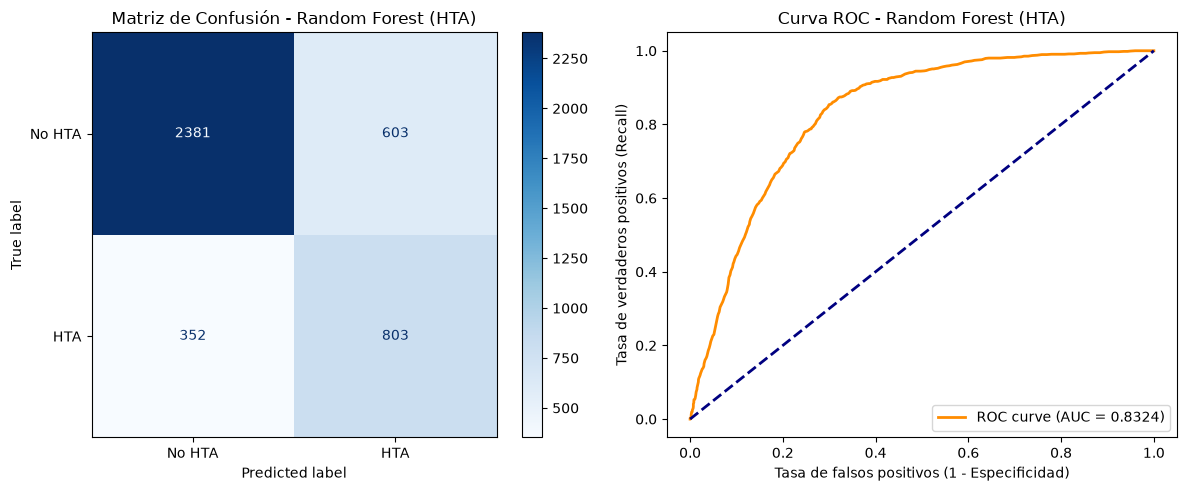

In [9]:
# ========================================================
# EVALUACIÓN RANDOM FOREST ('class_weight') - HIPERTENSIÓN
# ========================================================

# Predicciones 
y_pred_rf_hta_class_weight = rf_hta_class_weight.predict(X_test_hta)
y_proba_rf_hta_class_weight = rf_hta_class_weight.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA)")
print(classification_report(y_test_hta, y_pred_rf_hta_class_weight, digits=4))

# ROC-AUC 
auc_rf_hta_class_weight = roc_auc_score(y_test_hta, y_proba_rf_hta_class_weight)
print(f"ROC-AUC Score: {auc_rf_hta_class_weight:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_hta_class_weight = confusion_matrix(y_test_hta, y_pred_rf_hta_class_weight)
disp_rf_hta_class_weight = ConfusionMatrixDisplay(confusion_matrix=cm_rf_hta_class_weight, display_labels=["No HTA", "HTA"])
disp_rf_hta_class_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest (HTA)")

# Curva ROC
fpr_rf_hta_class_weight, tpr_rf_hta_class_weight, _ = roc_curve(y_test_hta, y_proba_rf_hta_class_weight)
axes[1].plot(fpr_rf_hta_class_weight, tpr_rf_hta_class_weight, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_hta_class_weight:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA) FACTOR ADULTO / BALANCEADO
              precision    recall  f1-score   support

           0     0.8801    0.7822    0.8282      2984
           1     0.5629    0.7247    0.6336      1155

    accuracy                         0.7661      4139
   macro avg     0.7215    0.7534    0.7309      4139
weighted avg     0.7916    0.7661    0.7739      4139

ROC-AUC Score: 0.8312


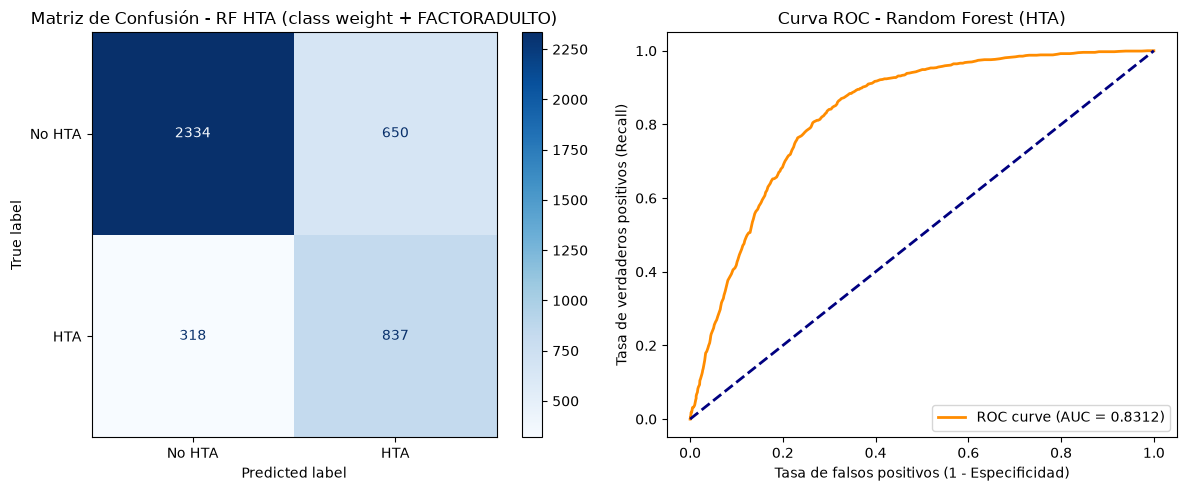

In [10]:
# ========================================================================
# EVALUACIÓN RANDOM FOREST ('class_weight' + FACTORADULTO) - HIPERTENSIÓN
# ========================================================================

# Predicciones 
y_pred_rf_hta = rf_hta.predict(X_test_hta)
y_proba_rf_hta = rf_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST (HTA) FACTOR ADULTO / BALANCEADO")
print(classification_report(y_test_hta, y_pred_rf_hta, digits=4))

# ROC-AUC 
auc_rf_hta = roc_auc_score(y_test_hta, y_proba_rf_hta)
print(f"ROC-AUC Score: {auc_rf_hta:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_hta = confusion_matrix(y_test_hta, y_pred_rf_hta)
disp_rf_hta = ConfusionMatrixDisplay(confusion_matrix=cm_rf_hta.astype(int), display_labels=["No HTA", "HTA"])
disp_rf_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - RF HTA (class weight + FACTORADULTO)")

# Curva ROC
fpr_rf_hta, tpr_rf_hta, _ = roc_curve(y_test_hta, y_proba_rf_hta)
axes[1].plot(fpr_rf_hta, tpr_rf_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE
              precision    recall  f1-score   support

           0     0.8253    0.8710    0.8475      2984
           1     0.6111    0.5238    0.5641      1155

    accuracy                         0.7741      4139
   macro avg     0.7182    0.6974    0.7058      4139
weighted avg     0.7656    0.7741    0.7685      4139

ROC-AUC Score: 0.8316


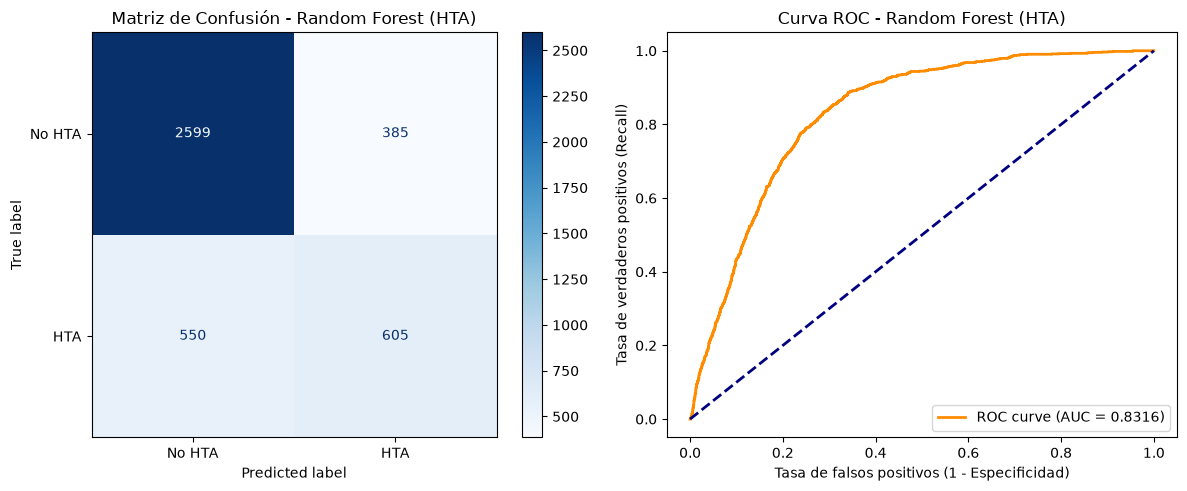

In [12]:
# ===============================
# EVALUACIÓN RANDOM FOREST SMOTE 
# ===============================

# Predicciones 
y_pred_rf_smote_hta = rf_smote_hta.predict(X_test_hta)
y_proba_rf_smote_hta = rf_smote_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE")
print(classification_report(y_test_hta, y_pred_rf_smote_hta, digits=4))

# ROC-AUC 
auc_rf_smote_hta = roc_auc_score(y_test_hta, y_proba_rf_smote_hta)
print(f"ROC-AUC Score: {auc_rf_smote_hta:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_smote_hta = confusion_matrix(y_test_hta, y_pred_rf_smote_hta)
disp_rf_smote_hta = ConfusionMatrixDisplay(confusion_matrix=cm_rf_smote_hta, display_labels=["No HTA", "HTA"])
disp_rf_smote_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest (HTA)")

# Curva ROC
fpr_rf_smote_hta, tpr_rf_smote_hta, _ = roc_curve(y_test_hta, y_proba_rf_smote_hta)
axes[1].plot(fpr_rf_smote_hta, tpr_rf_smote_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_smote_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS
              precision    recall  f1-score   support

           0     0.9053    0.7366    0.8123      2984
           1     0.5406    0.8009    0.6455      1155

    accuracy                         0.7545      4139
   macro avg     0.7229    0.7687    0.7289      4139
weighted avg     0.8035    0.7545    0.7657      4139

ROC-AUC Score: 0.8324


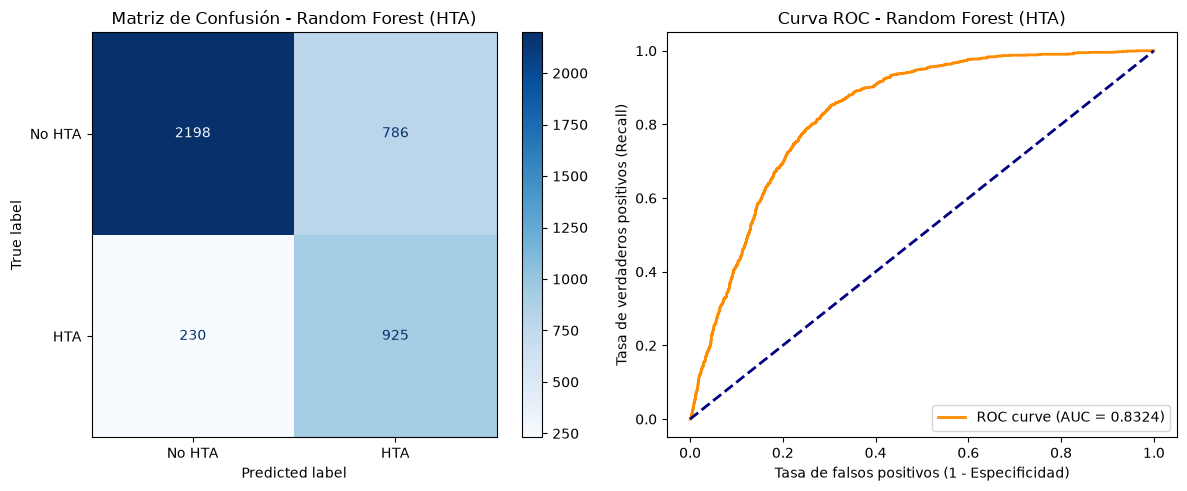

In [13]:
# ===========================================
# EVALUACIÓN RANDOM FOREST C/ PESOS DINÁMICOS
# ===========================================

# Predicciones 
y_pred_rf_subsample = rf_subsample_hta.predict(X_test_hta)
y_proba_rf_subsample = rf_subsample_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS")
print(classification_report(y_test_hta, y_pred_rf_subsample, digits=4))

# ROC-AUC 
auc_rf_subsample = roc_auc_score(y_test_hta, y_proba_rf_subsample)
print(f"ROC-AUC Score: {auc_rf_subsample:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_subsample = confusion_matrix(y_test_hta, y_pred_rf_subsample)
disp_rf_subsample = ConfusionMatrixDisplay(confusion_matrix=cm_rf_subsample, display_labels=["No HTA", "HTA"])
disp_rf_subsample.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest (HTA)")

# Curva ROC
fpr_rf_subsample, tpr_rf_subsample, _ = roc_curve(y_test_hta, y_proba_rf_subsample)
axes[1].plot(fpr_rf_subsample, tpr_rf_subsample, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_subsample:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (HTA)
              precision    recall  f1-score   support

           0     0.8882    0.7664    0.8228      2984
           1     0.5543    0.7506    0.6377      1155

    accuracy                         0.7620      4139
   macro avg     0.7213    0.7585    0.7303      4139
weighted avg     0.7950    0.7620    0.7712      4139

ROC-AUC Score: 0.8314


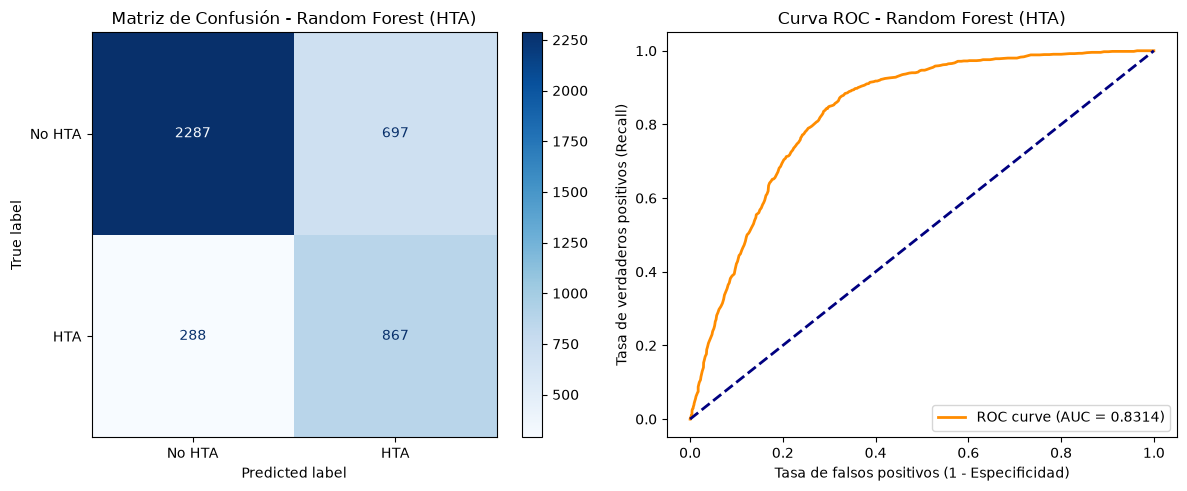

In [14]:
# ====================================
# EVALUACIÓN  BALANCED RANDOM FOREST 
# ====================================

# Predicciones 
y_pred_brf_hta = brf_hta.predict(X_test_hta)
y_proba_brf_hta = brf_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (HTA)")
print(classification_report(y_test_hta, y_pred_brf_hta, digits=4))

# ROC-AUC 
auc_brf_hta = roc_auc_score(y_test_hta, y_proba_brf_hta)
print(f"ROC-AUC Score: {auc_brf_hta:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_brf_hta = confusion_matrix(y_test_hta, y_pred_brf_hta)
disp_brf_hta = ConfusionMatrixDisplay(confusion_matrix=cm_brf_hta, display_labels=["No HTA", "HTA"])
disp_brf_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest (HTA)")

# Curva ROC
fpr_brf_hta, tpr_brf_hta, _ = roc_curve(y_test_hta, y_proba_brf_hta)
axes[1].plot(fpr_brf_hta, tpr_brf_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_brf_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

,Umbral,Recall Diabetes,Precisión Diabetes,F1-Score,FN (Diabéticos No Detectados)
0,0.20,98.18%,36.43%,0.5314,21
1,0.25,96.45%,39.32%,0.5587,40
2,0.30,94.55%,42.26%,0.5841,63
3,0.35,92.73%,44.81%,0.6042,84
4,0.40,91.26%,47.50%,0.6248,100
5,0.45,88.66%,49.83%,0.6380,131
6,0.50,84.16%,51.84%,0.6416,183


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST OPTIMIZADO
              precision    recall  f1-score   support

           0     0.9192    0.6974    0.7931      2984
           1     0.5184    0.8416    0.6416      1155

    accuracy                         0.7376      4139
   macro avg     0.7188    0.7695    0.7173      4139
weighted avg     0.8073    0.7376    0.7508      4139

ROC-AUC Score: 0.8327


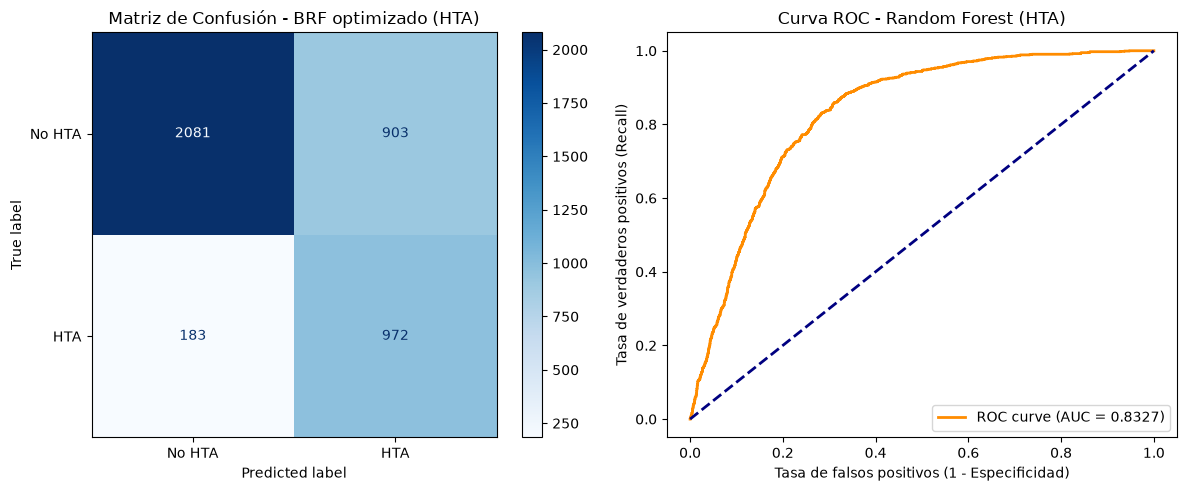

In [15]:
# =============================================
# EVALUACIÓN Balanced Random Forest optimizado 
# =============================================

# Predicciones 
y_pred_opt = brf_opt.predict(X_test_hta)
y_proba_opt = brf_opt.predict_proba(X_test_hta)[:, 1]

# 5. Barrido de Umbrales
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
resultados = []

for u in umbrales:
    y_pred_u = (y_proba_opt >= u).astype(int)
    rep = classification_report(y_test_hta, y_pred_u, output_dict=True)

    resultados.append(
        {
            "Umbral": u,
            "Recall Diabetes": f"{rep['1']['recall']*100:.2f}%",
            "Precisión Diabetes": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Diabéticos No Detectados)": int(
                (1 - rep["1"]["recall"]) * rep["1"]["support"]
            ),
        }
    )

df_umbrales = pd.DataFrame(resultados)
display(df_umbrales)

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST OPTIMIZADO")
print(classification_report(y_test_hta, y_pred_opt, digits=4))

# ROC-AUC 
auc_opt_hta = roc_auc_score(y_test_hta, y_proba_opt)
print(f"ROC-AUC Score: {auc_opt_hta:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_opt_hta = confusion_matrix(y_test_hta, y_pred_opt)
disp_opt_hta = ConfusionMatrixDisplay(confusion_matrix=cm_opt_hta, display_labels=["No HTA", "HTA"])
disp_opt_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF optimizado (HTA)")

# Curva ROC
fpr_opt_hta, tpr_opt_hta, _ = roc_curve(y_test_hta, y_proba_opt)
axes[1].plot(fpr_opt_hta, tpr_opt_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_opt_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


# SVM

In [5]:
# Cargar datos 
svm_hta_cw = joblib.load("../models/svm_hta_cw.joblib")
svm_hta = joblib.load("../models/svm_hta.joblib")
svm_hta_smote = joblib.load("../models/svm_hta_smote")

INFORME DE CLASIFICACIÓN - SVM (HTA)
              precision    recall  f1-score   support

           0     0.9121    0.7061    0.7960      2984
           1     0.5205    0.8242    0.6381      1155

    accuracy                         0.7391      4139
   macro avg     0.7163    0.7652    0.7170      4139
weighted avg     0.8028    0.7391    0.7519      4139

ROC-AUC Score: 0.8241


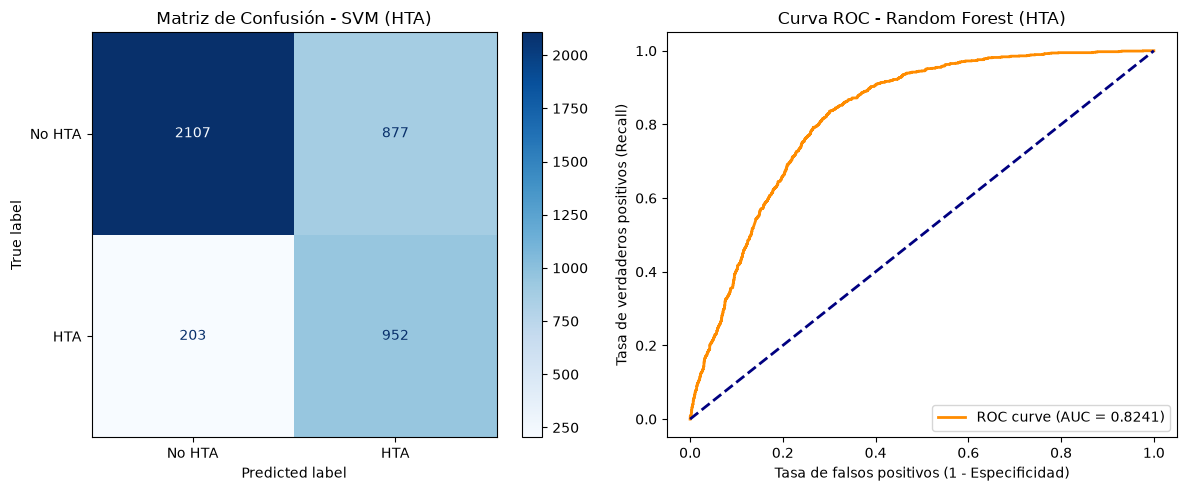

In [6]:
# ==============================================
# EVALUACIÓN SVM 'class_weight' - HIPERTENSIÓN
# ==============================================

# Predicciones 
y_pred_svm_hta_cw = svm_hta_cw.predict(X_test_hta)
y_pred_proba_svm_hta_cw = svm_hta_cw.predict_proba(X_test_hta)[:, 1]



print("INFORME DE CLASIFICACIÓN - SVM (HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta_cw, digits=4))

# ROC-AUC
auc_svm_hta_cw = roc_auc_score(y_test_hta, y_pred_proba_svm_hta_cw)
print(f"ROC-AUC Score: {auc_svm_hta_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta_cw = confusion_matrix(y_test_hta,y_pred_svm_hta_cw)
disp_svm_hta_cw = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta_cw, display_labels=["No HTA", "HTA"])
disp_svm_hta_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM (HTA)")

# CURVA ROC 
fpr_svm_hta_cw, tpr_svm_hta_cw, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta_cw)
axes[1].plot(fpr_svm_hta_cw, tpr_svm_hta_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta_cw:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - SVM (HTA)
              precision    recall  f1-score   support

           0     0.8060    0.8117    0.8088      2984
           1     0.5044    0.4952    0.4998      1155

    accuracy                         0.7234      4139
   macro avg     0.6552    0.6535    0.6543      4139
weighted avg     0.7218    0.7234    0.7226      4139

ROC-AUC Score: 0.7442


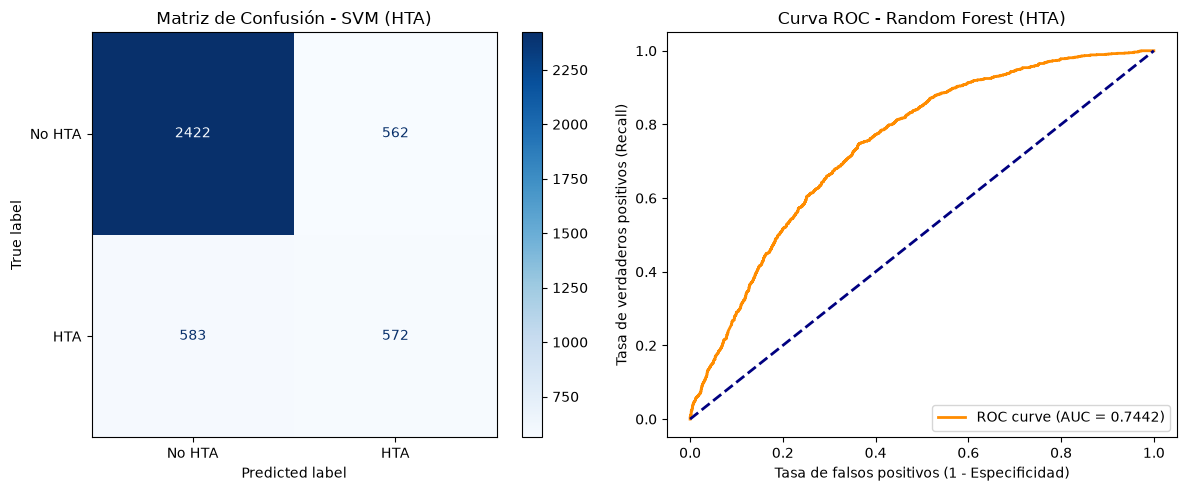

In [7]:
# ===============================================================
# EVALUACIÓN SVM 'class_weight' + 'sample_weight' - HIPERTENSIÓN
# ===============================================================

# Predicciones 
y_pred_svm_hta = svm_hta.predict(X_test_hta)
y_pred_proba_svm_hta = svm_hta.predict_proba(X_test_hta)[:, 1]

print("INFORME DE CLASIFICACIÓN - SVM (HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta, digits=4))

# ROC-AUC
auc_svm_hta = roc_auc_score(y_test_hta, y_pred_proba_svm_hta)
print(f"ROC-AUC Score: {auc_svm_hta:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta = confusion_matrix(y_test_hta,y_pred_svm_hta)
disp_svm_hta = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta, display_labels=["No HTA", "HTA"])
disp_svm_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM (HTA)")

# CURVA ROC 
fpr_svm_hta, tpr_svm_hta, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta)
axes[1].plot(fpr_svm_hta, tpr_svm_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - SVM CON SMOTE (HTA)
              precision    recall  f1-score   support

           0     0.8389    0.8358    0.8373      2984
           1     0.5798    0.5853    0.5825      1155

    accuracy                         0.7659      4139
   macro avg     0.7093    0.7105    0.7099      4139
weighted avg     0.7666    0.7659    0.7662      4139

ROC-AUC Score: 0.8191


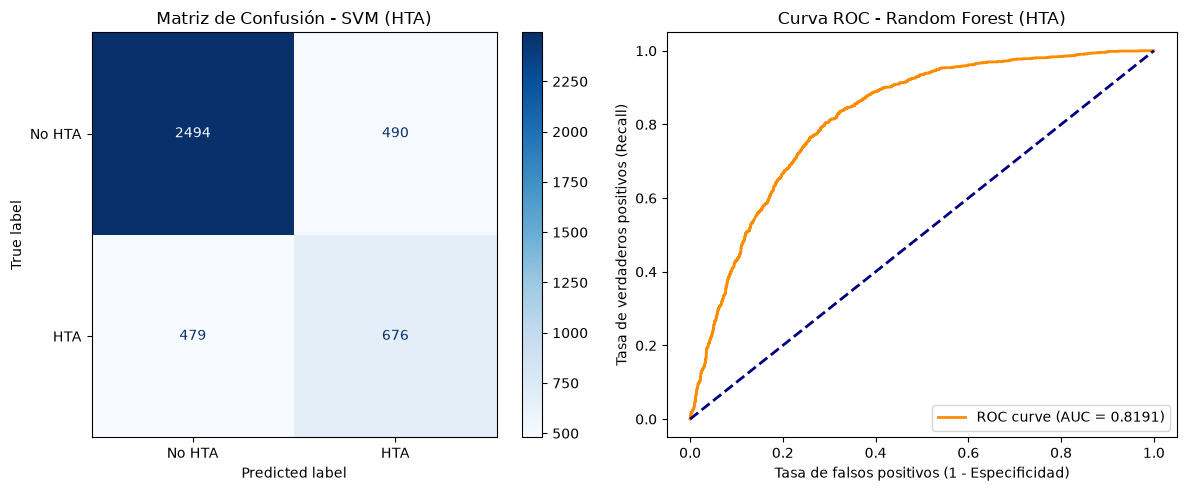

In [8]:
# ========================
# EVALUACIÓN SVM CON SMOTE
# ========================

# Predicciones 
y_pred_svm_hta_smote = svm_hta_smote.predict(X_test_hta)
y_pred_proba_svm_hta_smote = svm_hta_smote.predict_proba(X_test_hta)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM CON SMOTE (HTA)")
print(classification_report(y_test_hta, y_pred_svm_hta_smote, digits=4))

# ROC-AUC
auc_svm_hta_smote = roc_auc_score(y_test_hta, y_pred_proba_svm_hta_smote)
print(f"ROC-AUC Score: {auc_svm_hta_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_hta_smote = confusion_matrix(y_test_hta,y_pred_svm_hta_smote)
disp_svm_hta_smote = ConfusionMatrixDisplay(confusion_matrix=cm_svm_hta_smote, display_labels=["No HTA", "HTA"])
disp_svm_hta_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM (HTA)")

# CURVA ROC 
fpr_svm_hta_smote, tpr_svm_hta_smote, _ = roc_curve(y_test_hta, y_pred_proba_svm_hta_smote)
axes[1].plot(fpr_svm_hta_smote, tpr_svm_hta_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_hta_smote:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# EVALUACIÓN MODELOS XGBOOST

In [9]:
# CARGAR DATOS

import joblib

xgb_model_cw_hta = joblib.load("../models/xgb_model_cw_hta.joblib")
xgb_model_hta = joblib.load("../models/xgb_model_hta.joblib")
xgb_model_smote_hta = joblib.load("../models/xgb_model_smote_hta.joblib")

INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (HTA)
              precision    recall  f1-score   support

           0     0.9022    0.7386    0.8122      2984
           1     0.5401    0.7931    0.6426      1155

    accuracy                         0.7538      4139
   macro avg     0.7211    0.7658    0.7274      4139
weighted avg     0.8011    0.7538    0.7649      4139

ROC-AUC Score: 0.8295


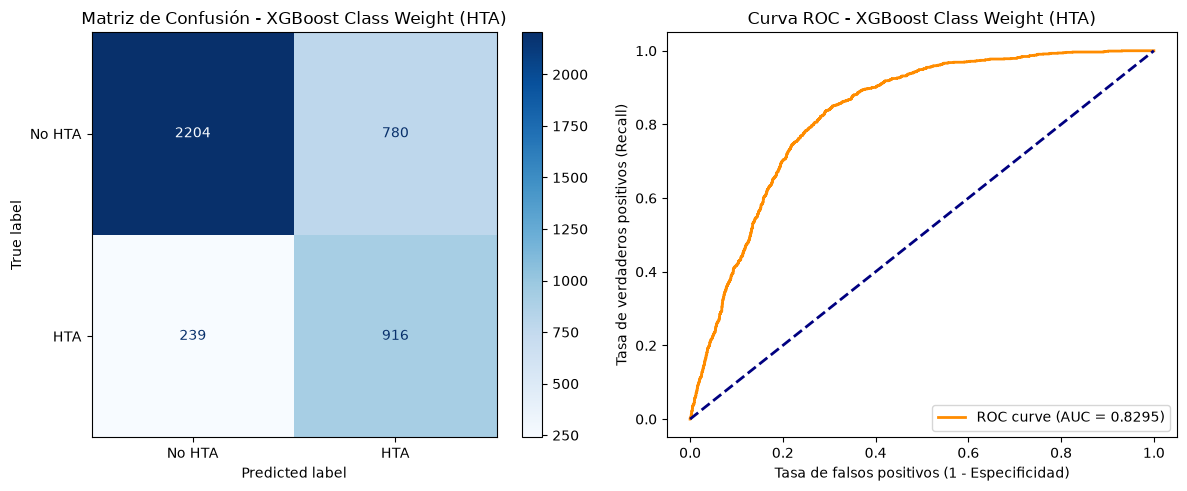

In [8]:
# ===============================================
# EVALUACIÓN XGBOOST 'class_weight' - HIPERTENSIÓN
# ===============================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_hta_cw = xgb_model_cw_hta.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_hta_cw = xgb_model_cw_hta.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_hta_cw, digits=4))

# ROC-AUC
auc_xgb_hta_cw = roc_auc_score(y_test_hta, y_pred_proba_xgb_hta_cw)
print(f"ROC-AUC Score: {auc_xgb_hta_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_hta_cw = confusion_matrix(y_test_hta, y_pred_xgb_hta_cw)
disp_xgb_hta_cw = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_hta_cw, display_labels=["No HTA", "HTA"])
disp_xgb_hta_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost Class Weight (HTA)")

# Curva ROC
fpr_xgb_hta_cw, tpr_xgb_hta_cw, _ = roc_curve(y_test_hta, y_pred_proba_xgb_hta_cw)
axes[1].plot(fpr_xgb_hta_cw, tpr_xgb_hta_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_hta_cw:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost Class Weight (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (HTA)
              precision    recall  f1-score   support

           0     0.9022    0.7386    0.8122      2984
           1     0.5401    0.7931    0.6426      1155

    accuracy                         0.7538      4139
   macro avg     0.7211    0.7658    0.7274      4139
weighted avg     0.8011    0.7538    0.7649      4139

ROC-AUC Score: 0.8295


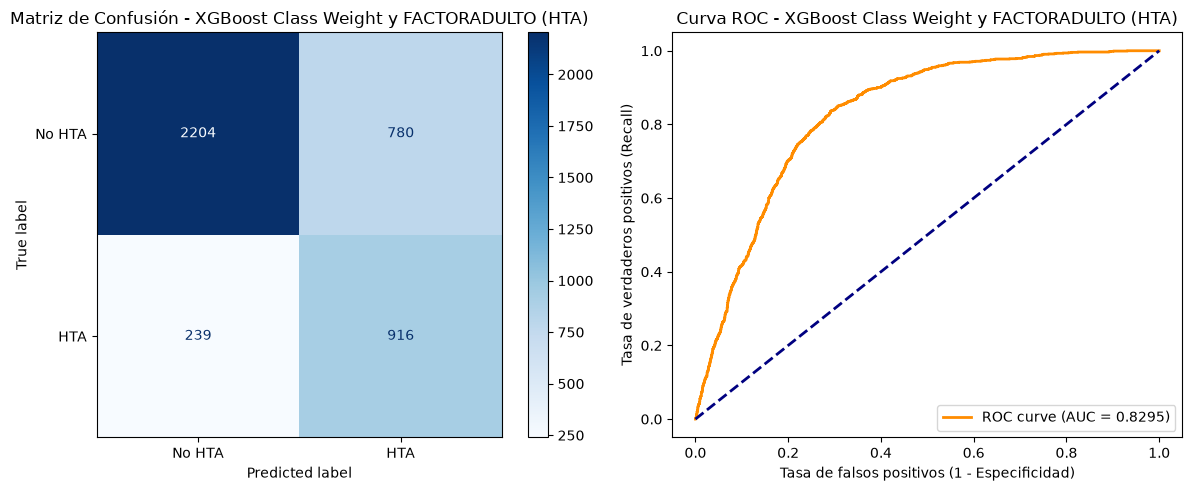

In [10]:
# ===========================================================
# EVALUACIÓN XGBOOST 'class_weight' y FACTORADULTO - HIPERTENSIÓN
# ===========================================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_hta = xgb_model_hta.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_hta = xgb_model_hta.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_hta, digits=4))

# ROC-AUC
auc_xgb_hta = roc_auc_score(y_test_hta, y_pred_proba_xgb_hta)
print(f"ROC-AUC Score: {auc_xgb_hta:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_hta = confusion_matrix(y_test_hta, y_pred_xgb_hta)
disp_xgb_hta = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_hta, display_labels=["No HTA", "HTA"])
disp_xgb_hta.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost Class Weight y FACTORADULTO (HTA)")

# Curva ROC
fpr_xgb_hta, tpr_xgb_hta, _ = roc_curve(y_test_hta, y_pred_proba_xgb_hta)
axes[1].plot(fpr_xgb_hta, tpr_xgb_hta, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_hta:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost Class Weight y FACTORADULTO (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (HTA)
              precision    recall  f1-score   support

           0     0.8439    0.8458    0.8449      2984
           1     0.5993    0.5957    0.5975      1155

    accuracy                         0.7760      4139
   macro avg     0.7216    0.7208    0.7212      4139
weighted avg     0.7756    0.7760    0.7758      4139

ROC-AUC Score: 0.8315


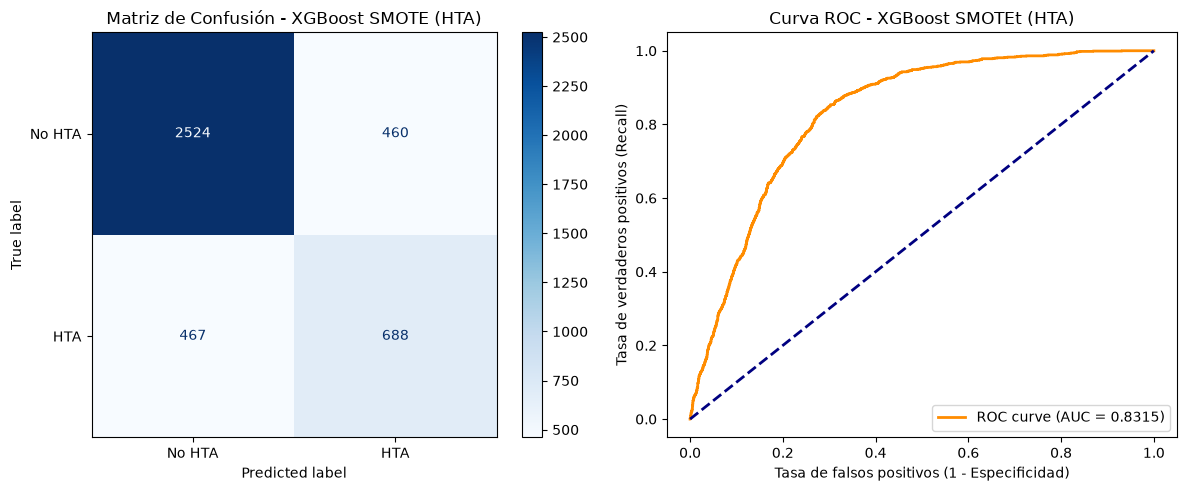

In [11]:
# ====================================
# EVALUACIÓN XGBOOST SMOTE - DIABETES
# ====================================


# Predicciones y probabilidades predichass
y_pred_proba_xgb_smote = xgb_model_smote_hta.predict_proba(X_test_hta)[:, 1]
y_pred_xgb_smote = xgb_model_smote_hta.predict(X_test_hta)

print("INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (HTA)")
print(classification_report(y_test_hta, y_pred_xgb_smote, digits=4))

# ROC-AUC
auc_xgb_smote = roc_auc_score(y_test_hta, y_pred_proba_xgb_smote)
print(f"ROC-AUC Score: {auc_xgb_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_smote = confusion_matrix(y_test_hta, y_pred_xgb_smote)
disp_xgb_smote = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_smote, display_labels=["No HTA", "HTA"])
disp_xgb_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost SMOTE (HTA)")

# Curva ROC
fpr_xgb_smote, tpr_xgb_smote, _ = roc_curve(y_test_hta, y_pred_proba_xgb_smote)
axes[1].plot(fpr_xgb_smote, tpr_xgb_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_smote:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost SMOTEt (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()